# Mask R-CNN vs YOLO-seg: instance segmentation on COCO

Instance segmentation (сегментация экземпляров): точность (AP) и скорость (FPS) двухстадийной и одностадийной моделей.

**Дата:** 2026-11-20. **Среда:** MacBook (Apple M4, 16 ГБ), PyTorch 2.15, torchvision 0.29, Ultralytics 8.4. CUDA нет, поэтому «GPU» в этой работе означает Apple MPS (Metal), а CPU означает 10 ядер M4.

**Рамки.** Модели не обучаем, сравниваем готовые веса COCO на COCO val2017 (модели его не видели при обучении). Главная метрика качества AP mask, потому что задача про маски. Скорость меряем как FPS при batch = 1, это режим видеопотока.

**Сокращения полного протокола ради времени прогона** (честно, чтобы цифры читались правильно):
- подвыборка из 500 фото зафиксирована (random_state=42), но AP посчитан на её первых **150** фото, одних и тех же для всех моделей;
- FPS на GPU меряется на **60** фото (10 из них прогрев, считаются 50), на CPU на **20** (5 прогрев, 15 в счёте);
- Mask R-CNN с min_size 512 не прогонялся, в компромиссе у Mask R-CNN одна точка (800).

In [1]:
import json, sys
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src.data import make_subset, download_images, image_dir, subset_tables
from src.experiments import accuracy_table, speed_table, display_name, label
from src.evaluate import load_gt
from src import viz
from src.run_all import N_AP

TABLES, FIGS = ROOT / "results" / "tables", ROOT / "results" / "figures"
FIGS.mkdir(parents=True, exist_ok=True)
pd.set_option("display.precision", 1)

## 1. Данные: подвыборка COCO val2017

Ожидание: около 7 объектов на фото, самый частый класс person, много мелких объектов (в COCO их примерно 40 %).

In [2]:
subset_json = make_subset(ROOT)            # 500 фото, random_state=42
img_dir = download_images(ROOT, subset_json)
images = json.loads(subset_json.read_text())["images"]
imgs, anns, cats = subset_tables(subset_json)
ap_ids = {im["id"] for im in images[:N_AP]}
summary = pd.DataFrame({
    "фото": [len(imgs), len(ap_ids)],
    "объектов": [len(anns), anns.image_id.isin(ap_ids).sum()],
    "из них iscrowd": [anns.iscrowd.sum(), anns[anns.image_id.isin(ap_ids)].iscrowd.sum()],
    "объектов на фото": [len(anns) / len(imgs), anns.image_id.isin(ap_ids).sum() / len(ap_ids)],
}, index=["вся подвыборка (500)", f"часть для AP ({N_AP})"])
summary.to_csv(TABLES / "subset_summary.csv"); display(summary)
top5 = anns.category.value_counts().head(5).rename("объектов").to_frame()
top5["доля, %"] = 100 * top5["объектов"] / len(anns)
top5.to_csv(TABLES / "top5_classes.csv"); display(top5)
sizes = anns["size"].value_counts(normalize=True).mul(100).rename("доля, %").to_frame()
display(sizes)

,фото,объектов,из них iscrowd,объектов на фото
вся подвыборка (500),500,3344,30,6.7
часть для AP (150),150,1054,9,7.0


,объектов,"доля, %"
category,,
person,927,27.7
chair,201,6.0
car,143,4.3
bottle,117,3.5
cup,111,3.3


,"доля, %"
size,
small,37.2
medium,36.1
large,26.7


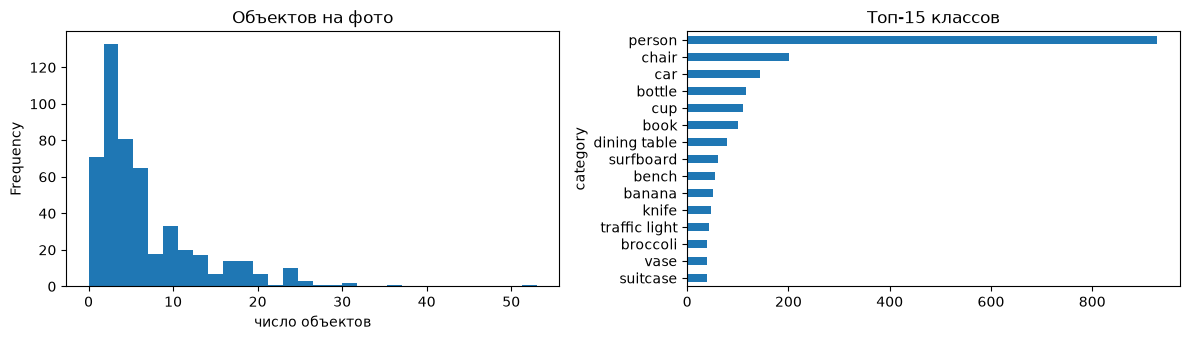

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
anns.groupby("image_id").size().reindex(imgs.id, fill_value=0).plot.hist(bins=30, ax=ax[0])
ax[0].set_title("Объектов на фото"); ax[0].set_xlabel("число объектов")
anns.category.value_counts().head(15)[::-1].plot.barh(ax=ax[1]); ax[1].set_title("Топ-15 классов")
fig.tight_layout(); fig.savefig(FIGS / "eda.png", dpi=110); plt.show()

Превью: 6 случайных фото подвыборки с эталонными масками COCO.

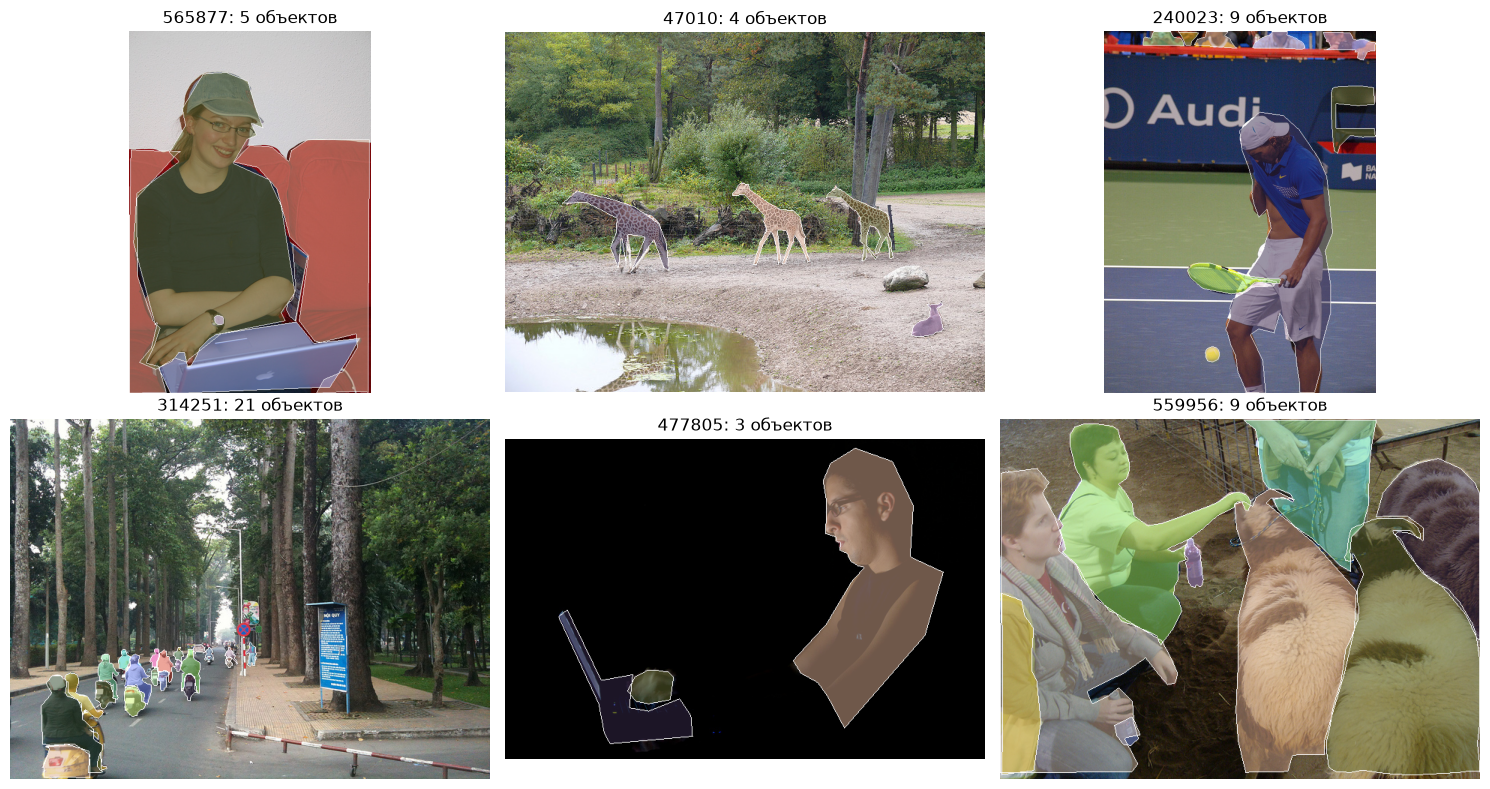

In [4]:
gt = load_gt(subset_json)
rng = np.random.default_rng(42)
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, im in zip(axes.flat, rng.choice(images, 6, replace=False)):
    ax.imshow(viz.overlay(viz.read_rgb(img_dir / im["file_name"]), viz.gt_masks(gt, im["id"])))
    ax.set_title(f"{im['id']}: {len(gt.getAnnIds(imgIds=im['id']))} объектов"); ax.axis("off")
fig.tight_layout(); fig.savefig(FIGS / "preview_gt.png", dpi=90); plt.show()

**Вывод.** Распределение похоже на весь COCO: в среднем около 7 объектов на фото, person сильно впереди остальных классов, мелкие объекты составляют большую долю. Значит, APs будет заметно влиять на общий AP.

## 2. Модели: параметры и GFLOPs

GFLOPs считаем сами через `torch.utils.flop_counter` (FLOPs = 2 × MAC): у YOLO на 640×640, у Mask R-CNN на 800×800.

In [5]:
passport = pd.read_csv(TABLES / "passport.csv")
passport["ref params, млн"] = [46.4, 2.7, 10.4]; passport["ref GFLOPs"] = [333.6, 9.3, 34.5]
display(passport)

,model,params_m,gflops,input,"ref params, млн",ref GFLOPs
0,Mask R-CNN v2,46.4,667.2,800×800,46.4,333.6
1,YOLO26n-seg,3.1,10.4,640×640,2.7,9.3
2,YOLO26s-seg,11.5,37.3,640×640,10.4,34.5


Наши числа сверены со справочными из документации (столбцы ref). Mask R-CNN тяжелее YOLO26s-seg примерно в 10 раз по вычислениям, а YOLO26n-seg примерно в 36 раз.

## 3. Предсказания в формате COCO

Код в `src/predict.py`. Ловушки, которые там учтены:
- YOLO нумерует классы 0–79, а у COCO id идут от 1 до 90 с пропусками, поэтому пересчёт через `coco80_to_coco91_class()`; Mask R-CNN сразу отдаёт id COCO;
- рамки переводятся из [x1, y1, x2, y2] в COCO-формат [x, y, w, h];
- маски строятся в размере исходного фото: у YOLO через `retina_masks=True`, у Mask R-CNN через порог 0.5 по вероятностям; затем RLE (`pycocotools.mask.encode`, Fortran-порядок, counts в str);
- порог уверенности 0.001 у обеих моделей (у Mask R-CNN `box_score_thresh=0.001` вместо 0.05), не больше 100 детекций на фото, как `maxDets=100` в COCOeval.

## 4. Точность: AP по COCOeval

Ожидание: AP mask ниже AP box у всех моделей; Mask R-CNN лучше на мелких объектах за счёт входа 800 px против 640.

In [6]:
ap = accuracy_table(ROOT, subset_json, images[:N_AP], img_dir)
ap["конфигурация"] = [label(m, s) for m, s in zip(ap["model"], ap["size"])]
main_cfg = [("mrcnn", 800), ("YOLO26n-seg", 640), ("YOLO26s-seg", 640)]
ap_main = pd.concat([ap[(ap.model == m) & (ap["size"] == s)] for m, s in main_cfg])
ap_main.index = [display_name(m) for m in ap_main.model]
cols = ["AP mask", "AP box", "AP50 mask", "AP75 mask", "APs mask", "APm mask", "APl mask"]
ap_main[cols].to_csv(TABLES / "ap_main.csv"); display(ap_main[cols])
ref = pd.DataFrame({"AP box (док.)": [47.4, 39.6, 47.3], "AP mask (док.)": [41.8, 33.9, 40.0]}, index=ap_main.index)
display(ap_main[["AP box", "AP mask"]].join(ref))

,AP mask,AP box,AP50 mask,AP75 mask,APs mask,APm mask,APl mask
Mask R-CNN v2,50.3,57.5,72.8,54.9,34.7,52.0,62.9
YOLO26n-seg,40.6,48.3,60.4,45.0,21.4,43.2,57.4
YOLO26s-seg,45.3,54.0,66.2,48.6,25.9,49.4,59.1


,AP box,AP mask,AP box (док.),AP mask (док.)
Mask R-CNN v2,57.5,50.3,47.4,41.8
YOLO26n-seg,48.3,40.6,39.6,33.9
YOLO26s-seg,54.0,45.3,47.3,40.0


## 5. Скорость: FPS

Время засекается между `torch.mps.synchronize()` до и после кадра, batch = 1, первые кадры (прогрев) не считаются. «Сеть» означает только прямой проход по уже подготовленному тензору, «полный цикл» включает чтение фото, предобработку, сеть, постобработку и маски на CPU. Порог уверенности при замерах скорости 0.25.

In [7]:
sp = speed_table(ROOT, img_dir, images)
sp["name"] = [display_name(m) for m in sp.model]
sp["setting"] = np.where(sp.dev == "cpu", "CPU", np.where(sp.half, "MPS FP16", "MPS FP32"))
main = sp[[(m, s) in main_cfg for m, s in zip(sp.model, sp["size"])]]
fps = main.pivot_table(index="name", columns=["mode", "setting"], values="fps").round(1)
fps = fps.reindex(["Mask R-CNN v2", "YOLO26n-seg", "YOLO26s-seg"])
fps.to_csv(TABLES / "fps_main.csv"); display(fps)
if "error" in sp: display(sp[sp["error"].notna()][["name", "setting", "mode", "error"]])
lat = main.pivot_table(index="name", columns=["mode", "setting"], values="ms_mean").round(1)
display(lat.rename_axis(columns=["mode", "мс на кадр"]))

mode           full                   model                  
setting         CPU MPS FP16 MPS FP32   CPU MPS FP16 MPS FP32
name                                                         
Mask R-CNN v2   0.4      1.2      1.3   0.5      1.3      1.2
YOLO26n-seg    19.4     25.7     28.4  24.1      8.6     46.5
YOLO26s-seg    10.4     24.7     19.5  10.1     12.2     22.8

mode             full                     model                  
мс на кадр        CPU MPS FP16 MPS FP32     CPU MPS FP16 MPS FP32
name                                                             
Mask R-CNN v2  2367.1    845.2    764.9  2040.5    786.7    834.0
YOLO26n-seg      51.7     38.8     35.2    41.6    116.9     21.5
YOLO26s-seg      96.1     40.5     51.3    98.8     81.9     43.9

## 6. Компромисс скорость и точность

Ожидание: меньший вход быстрее, но AP mask (особенно APs) падает.

,конфигурация,AP mask,APs mask,AP box,fps
0,Mask R-CNN v2 (min_size 800),50.3,34.7,57.5,1.3
1,YOLO26n-seg (imgsz 320),32.3,7.5,37.8,34.6
2,YOLO26n-seg (imgsz 640),40.6,21.4,48.3,28.4
3,YOLO26n-seg (imgsz 960),41.0,26.9,48.4,22.9
4,YOLO26s-seg (imgsz 320),38.6,13.0,47.0,29.6
5,YOLO26s-seg (imgsz 640),45.3,25.9,54.0,19.5
6,YOLO26s-seg (imgsz 960),46.0,31.7,53.0,10.4


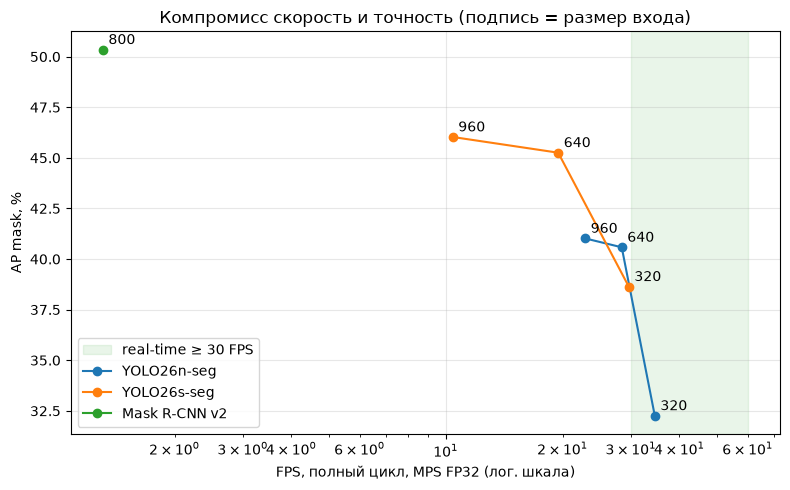

In [8]:
full = sp[(sp["mode"] == "full") & (sp.setting == "MPS FP32")][["model", "size", "fps"]]
tr = ap.merge(full, on=["model", "size"])
tr[["конфигурация", "AP mask", "APs mask", "AP box", "fps"]].to_csv(TABLES / "tradeoff.csv", index=False)
display(tr[["конфигурация", "AP mask", "APs mask", "AP box", "fps"]])
fig, ax = plt.subplots(figsize=(8, 5))
ax.axvspan(30, max(60, tr.fps.max() * 1.1), color="tab:green", alpha=0.1, label="real-time ≥ 30 FPS")
for m, g in tr.groupby("model"):
    g = g.sort_values("size")
    ax.plot(g.fps, g["AP mask"], "o-", label=display_name(m))
    for _, r in g.iterrows(): ax.annotate(str(r["size"]), (r.fps, r["AP mask"]), xytext=(4, 4), textcoords="offset points")
ax.set_xscale("log"); ax.set_xlabel("FPS, полный цикл, MPS FP32 (лог. шкала)"); ax.set_ylabel("AP mask, %")
ax.set_title("Компромисс скорость и точность (подпись = размер входа)"); ax.legend(); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(FIGS / "tradeoff.png", dpi=110); plt.show()

## 7. Качество масок глазами: 5 сложных фото

Выбираем фото с большим числом мелких объектов и сложных границ (`viz.pick_hard_images`). Показаны детекции со score ≥ 0.5. Что смотреть: края, тонкие детали (руки, ножки, спицы), перекрывающиеся объекты.

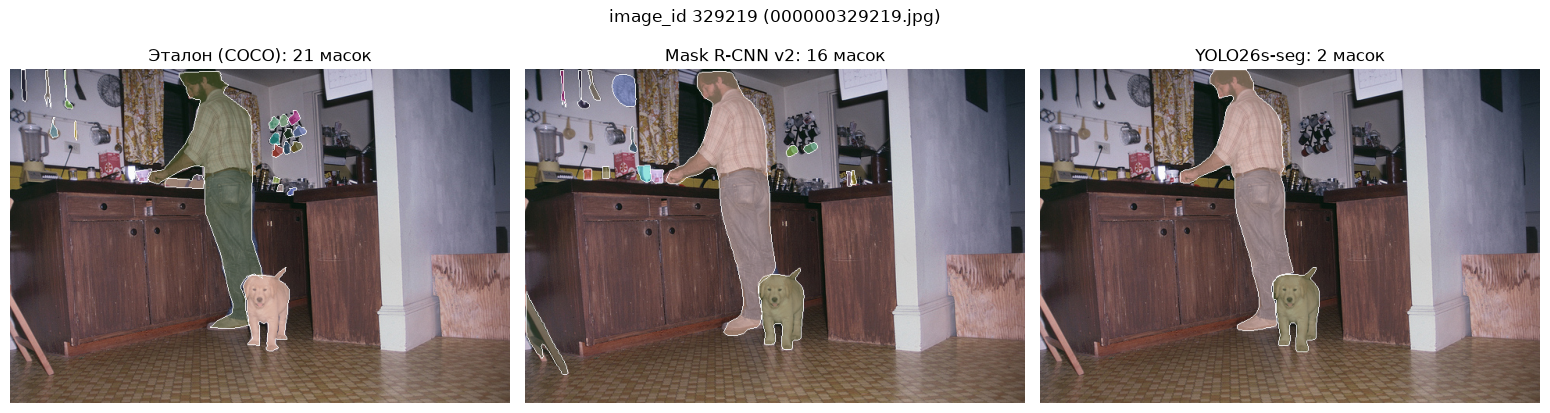

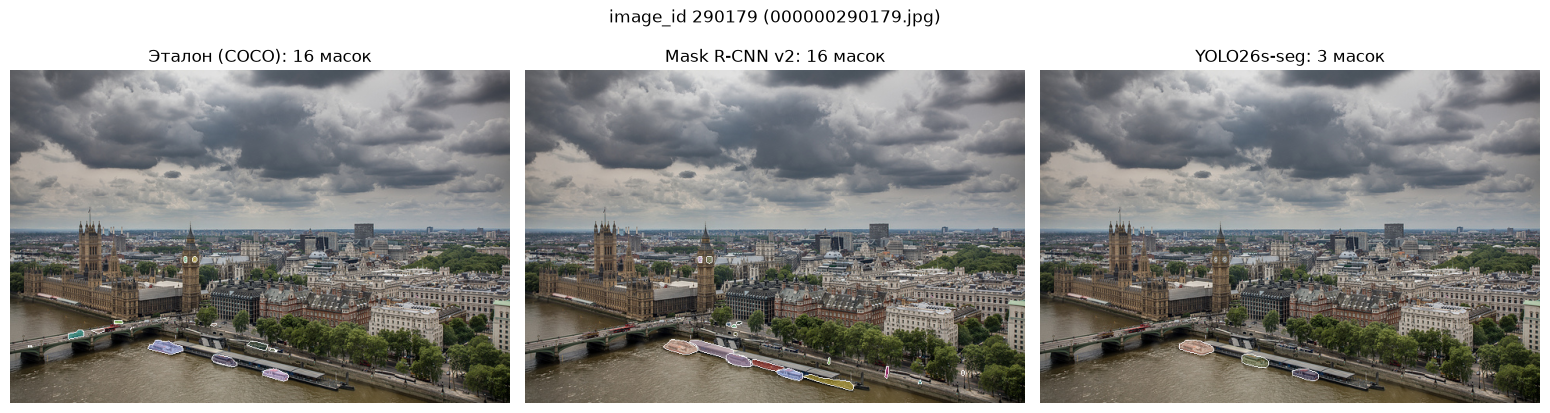

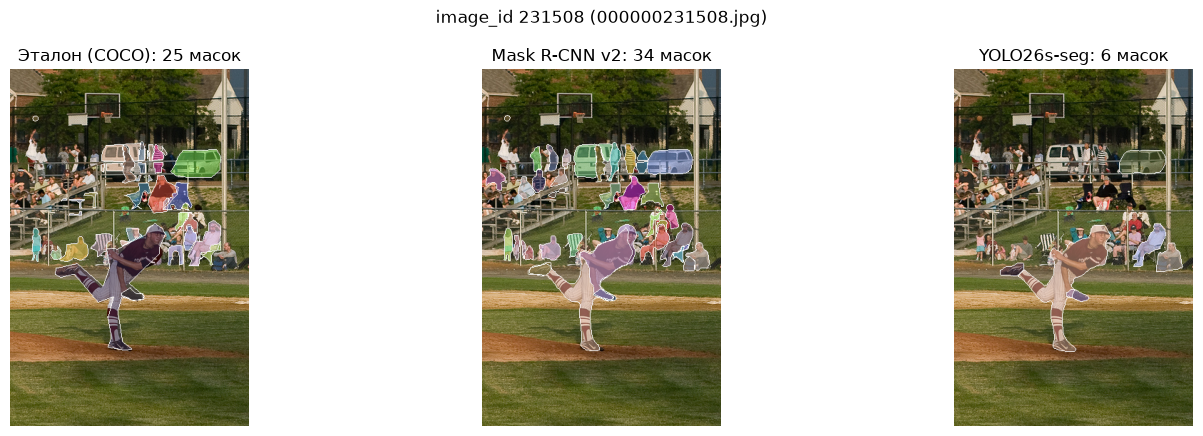

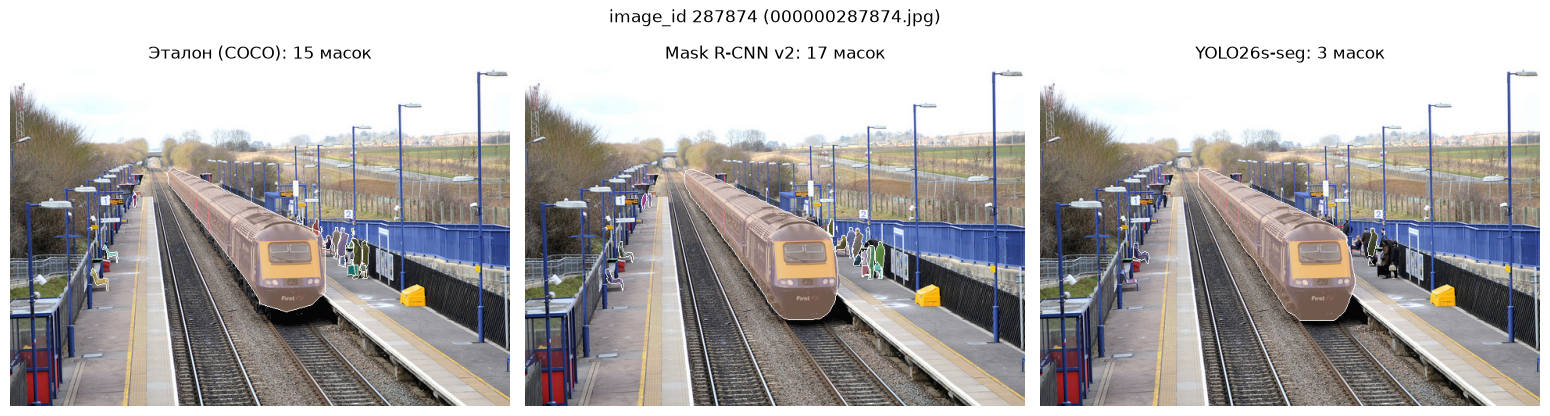

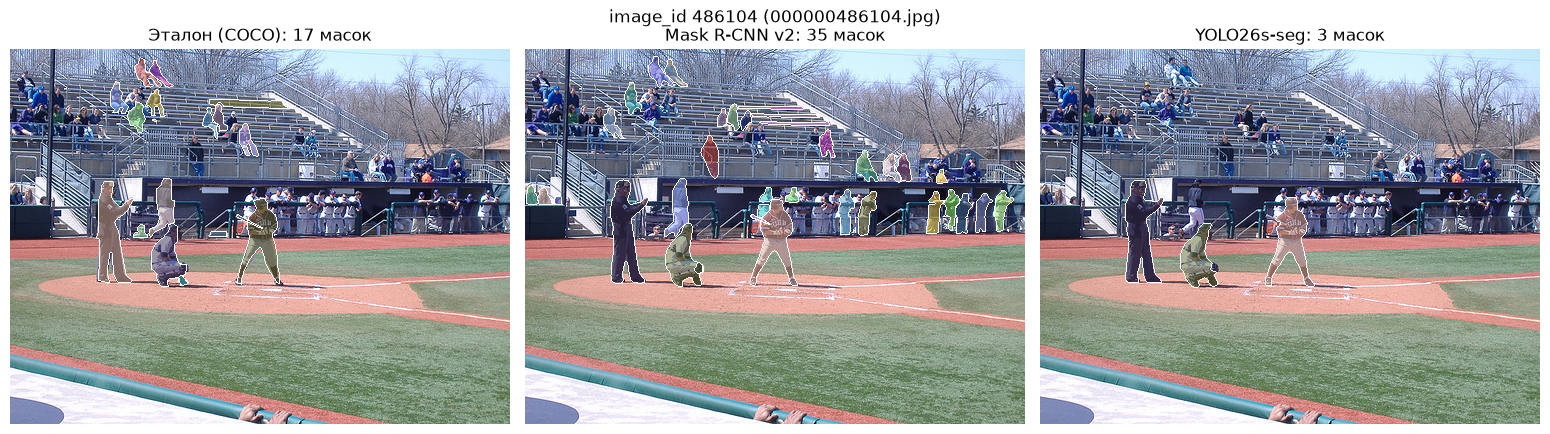

[329219, 290179, 231508, 287874, 486104]


In [9]:
preds = {"Mask R-CNN v2": viz.load_preds(ROOT / "results/preds/mrcnn_800.json"),
         "YOLO26s-seg": viz.load_preds(ROOT / "results/preds/YOLO26s-seg_640.json")}
hard = viz.pick_hard_images(anns[anns.image_id.isin(ap_ids)], k=5)
sample_dir = ROOT / "results" / "samples" / "mask_quality"
review = []
for iid in hard:
    p = sample_dir / f"{iid}_gt_mrcnn_yolo26s.png"
    viz.compare_figure(gt, img_dir, iid, preds, p); plt.show()
    review.append({"file": str(p.relative_to(ROOT)), "что проверить": "края, тонкие детали, слипание соседних объектов",
                   "лучше (MRCNN/YOLO/равно)": "", "оценка 1–5": "", "комментарий": "", "кто проверял": ""})
(ROOT / "results" / "review").mkdir(exist_ok=True)
pd.DataFrame(review).to_csv(ROOT / "results/review/mask_quality.csv", index=False)
print(hard)

## 8. Итоговая таблица и выводы

| Модель | AP mask | AP box | APs mask | Параметры, млн | GFLOPs | FPS MPS FP32 (полный цикл) | FPS MPS FP16 | FPS CPU |
|---|---|---|---|---|---|---|---|---|
| Mask R-CNN v2 (800) | 50.3 | 57.5 | 34.7 | 46.4 | 667 | 1.3 | 1.2 | 0.4 |
| YOLO26n-seg (640) | 40.6 | 48.3 | 21.4 | 3.1 | 10.4 | 28.4 | 25.7 | 19.4 |
| YOLO26s-seg (640) | 45.3 | 54.0 | 25.9 | 11.5 | 37.3 | 19.5 | 24.7 | 10.4 |

AP посчитан на 150 фото, поэтому числа выше документации (41.8 и 33.9/40.0 для масок): на малой выборке разброс несколько пунктов. **Порядок моделей совпадает с документацией**: Mask R-CNN > YOLO26s > YOLO26n. GFLOPs Mask R-CNN у нас 667, это ровно 2 × 333.6 из документации torchvision: torchvision считает MAC, а `FlopCounterMode` считает FLOPs = 2 × MAC. У YOLO параметры немного больше справочных (3.1 против 2.7), потому что мы считали модель до слияния Conv и BN.

**Почему AP mask ниже AP box.** У всех моделей разрыв составляет 7–9 пунктов. IoU масок считается по пикселям, и ошибки на границе бьют по нему сильнее, чем по рамке; маски строятся в низком разрешении (28×28 у Mask R-CNN, прототипы 160×160 у YOLO).

**Мелкие объекты.** Mask R-CNN заметно лучше: APs 34.7 против 25.9 у YOLO26s. Гипотеза про размер входа подтверждается: YOLO26s при imgsz 960 поднимает APs с 25.9 до 31.7, а при 320 роняет его до 13.0.

**Скорость.** На Apple MPS Mask R-CNN медленная, 1.3 FPS (около 0.8 с на кадр). Часть операций (RoIAlign, вставка масок) на MPS работает плохо, поэтому даже «чистая сеть» почти не быстрее полного цикла; на CUDA разрыв был бы меньше, но всё равно в разы. YOLO26n-seg даёт 28 FPS в полном цикле и 46 FPS как чистая сеть, YOLO26s-seg 20 FPS. FP16 на MPS почти ничего не дал (у s-seg в полном цикле 24.7 против 19.5, у n-seg прироста нет), а замер «только сеть» в FP16 оказался медленнее FP32. Его считаю ненадёжным: MPS плохо ускоряет half без Tensor Cores, а Ultralytics помечает `half` как устаревший. На CPU YOLO26n-seg держит 19 FPS, Mask R-CNN 0.4 FPS (2.4 с на кадр).

**Компромисс.** Real-time (≥ 30 FPS) на этом Маке дают только YOLO26n-seg при 320 (34.6 FPS, AP mask 32.3) и почти YOLO26s-seg при 320 (29.6 FPS, AP mask 38.6). YOLO26n-seg 640 и YOLO26s-seg 320 почти равны по скорости (28.4 и 29.6 FPS), но n-seg 640 точнее (40.6 против 38.6): при равной скорости выгоднее маленькая модель с большим входом, чем большая с маленьким. Mask R-CNN стоит отдельной точкой: самая точная и в 15–20 раз медленнее.

**Качество масок** (5 фото в `results/samples/mask_quality/`): у Mask R-CNN контуры крупных объектов сглажены из-за сетки 28×28; у YOLO на соседних объектах маски могут перетекать друг в друга, а мелкие объекты чаще пропускаются. Окончательная оценка глазами остаётся за человеком, таблица `results/review/mask_quality.csv`.

**Какую модель брать:**
- **Видео в реальном времени** (дрон, камера на перекрёстке): YOLO26-seg. На GPU берём s-seg (на CUDA с TensorRT это сотни FPS), на слабом железе n-seg или вход 320.
- **Офлайн-разметка с точными контурами:** Mask R-CNN (лучший AP mask и APs), либо крупная YOLO-seg с imgsz 960+.
- **Слабое устройство без GPU:** YOLO26n-seg, 19 FPS на CPU M4; лучше после экспорта в ONNX или CoreML.
- **Когда двухстадийная модель оправдана:** когда важны мелкие объекты и аккуратные маски, время не критично, нужна гибкость архитектуры (голова ключевых точек) или проект уже построен на torchvision или Detectron2.

**Ограничения:** AP посчитан на 150 фото, а не на 500; FPS на 60 и 20 кадрах; вместо CUDA использовался MPS; Mask R-CNN с min_size 512 не прогонялась.
